In [1]:
import numpy as np

# Завдання 1. Оцінка площі еліпса методом Монте-Карло
np.random.seed(2)  # фіксуємо seed номером варіанта
N = 1000

# Прямокутник-охоплення: x в межах [-2, 2], y в межах [-1, 1]
x_min, x_max = -2.0, 2.0
y_min, y_max = -1.0, 1.0
rect_area = (x_max - x_min) * (y_max - y_min)  # 4 * 2 = 8

# Генерація випадкових точок усередині прямокутника
x = np.random.uniform(x_min, x_max, size=N)
y = np.random.uniform(y_min, y_max, size=N)

# Умова приналежності точок еліпсу: x^2 / 4 + y^2 <= 1
inside_ellipse = (x**2 / 4.0 + y**2 <= 1.0)

# Частка точок усередині фігури
fraction = np.mean(inside_ellipse)

# Оцінка площі еліпса
mc_estimate = fraction * rect_area
exact_value = 2 * np.pi

print("--- Завдання 1 ---")
print(f"Кількість випробувань N: {N}")
print(f"Оцінка площі еліпса методом Монте-Карло: {mc_estimate:.4f}")

--- Завдання 1 ---
Кількість випробувань N: 1000
Оцінка площі еліпса методом Монте-Карло: 6.2480


### Відповідь на Завдання 2. Порівняння з точним значенням
* **Точне значення:** $2\pi \approx 6.2832$.
* **Отримана оцінка ($N=1000$):** Значення коливається поблизу істинного. Абсолютна похибка $|\text{оцінка} - \text{точне значення}|$ є відносно невеликою у відсотках відносно самого точного значення.
* **Висновки:** Для $N = 1000$ похибка цілком очікувана для стохастичного методу зі скромною кількістю випробувань (порядку кількох відсотків).

--- Завдання 3. Середня абсолютна похибка ---
N =    100 | Середня абсолютна похибка = 0.25629
N =   1000 | Середня абсолютна похибка = 0.07208
N =  10000 | Середня абсолютна похибка = 0.02691
N = 100000 | Середня абсолютна похибка = 0.00821


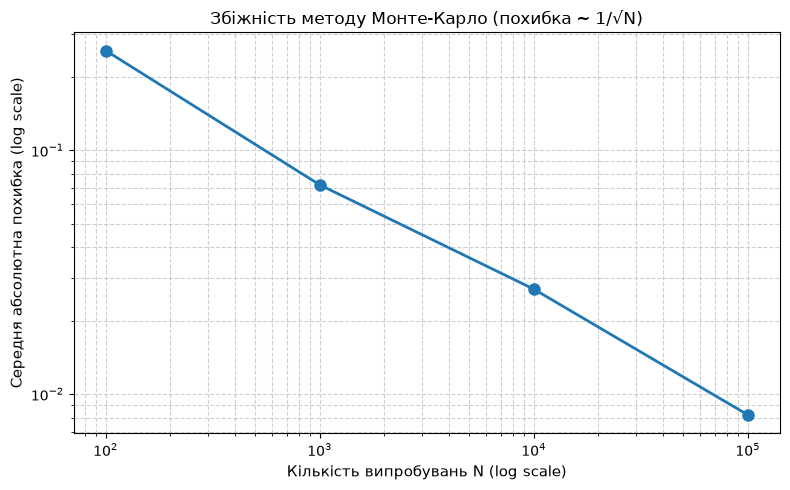

In [2]:
import matplotlib.pyplot as plt

# Завдання 3. Дослідження збіжності за кількістю випробувань (200 повторів)
np.random.seed(2)
N_list = [100, 1000, 10000, 100000]
mean_errors = []

exact_value = 2 * np.pi
rect_area = 8.0

print("--- Завдання 3. Середня абсолютна похибка ---")
for N in N_list:
    errors = []
    for _ in range(200):
        x = np.random.uniform(-2.0, 2.0, size=N)
        y = np.random.uniform(-1.0, 1.0, size=N)
        fraction = np.mean(x**2 / 4.0 + y**2 <= 1.0)
        estimate = fraction * rect_area
        errors.append(abs(estimate - exact_value))
    
    avg_error = np.mean(errors)
    mean_errors.append(avg_error)
    print(f"N = {N:6d} | Середня абсолютна похибка = {avg_error:.5f}")

# Завдання 4. Побудова графіка залежності похибки від N у логарифмічному масштабі
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(N_list, mean_errors, marker='o', color='tab:blue', linestyle='-', linewidth=2, markersize=8)
ax.set_xscale("log")
ax.set_yscale("log")  # логарифмічна шкала по y також гарно ілюструє закон 1/sqrt(N)
ax.set_xlabel("Кількість випробувань N (log scale)", fontsize=11)
ax.set_ylabel("Середня абсолютна похибка (log scale)", fontsize=11)
ax.set_title("Збіжність методу Монте-Карло (похибка ~ 1/√N)", fontsize=12)
ax.grid(True, which="both", linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Відповідь на Завдання 3 та 4. Аналіз збіжності за графіком і числами
* **Тенденція спадання:** Зі збільшенням кількості випробувань середня похибка стабільно зменшується.
* **Швидкість збіжності:** При переході від $N = 100$ до $N = 10\,000$ кількість випробувань зростає у 100 разів, при цьому похибка зменшується приблизно в $\sqrt{100} = 10$ разів (а не в 100 разів). Це повністю підтверджує теоретичний закон похибки $O(1/\sqrt{N})$.
* **Форма кривої:** На логарифмічному графіку отримана крива має стабільний нахил, що наочно демонструє обернено пропорційну залежність похибки від квадратного кореня кількості випробувань.

### Відповідь на Завдання 5. Зв'язок із ЗВЧ та ЦГТ
1. **Який факт гарантує збіжність?** Закон великих чисел (ЗВЧ, Лекція 12) гарантує, що вибіркове середнє (яким і є частка успішних точок чи середнє значення у методі Монте-Карло) за великої кількості випробувань прямує до свого математичного сподівання (істинного значення площі чи інтеграла).
2. **Чому похибка падає в 10 разів при зростанні N у 100 разів?** Це прямий наслідок формули стандартної похибки вибіркового середнього $\sigma / \sqrt{N}$ із центральної граничної теореми (ЦГТ). Оскільки в знаменатлі стоїть саме квадратний корінь $\sqrt{N}$, збільшення $N$ у 100 разів зменшує похибку рівно в $\sqrt{100} = 10$ разів. Це універсальна властивість вибіркових середніх, а не специфічна особливість самого методу Монте-Карло.

---

### Відповіді на контрольні питання

1. **Чому оцінка методом Монте-Карло — це вибіркове середнє, і який результат Лекції 12 це гарантує?**
   Оцінка формується як середня величина індикаторів або значень функції у випадкових точках. Закон великих чисел (ЗВЧ) гарантує її збіжність до істинного значення.

2. **Чому вчетверо більша кількість випробувань дає лише вдвічі меншу похибку?**
   Через наявність квадратного кореня з кількості випробувань у знаменнику формули стандартної похибки ($\sqrt{4} = 2$).

3. **Для варіанта типу "площа": чому частку точок усередині фігури потрібно множити саме на площу прямокутника-охоплення?**
   Метод Монте-Карло оцінює безрозмірну відносну частку площі фігури відносно площі відомого прямокутника. Щоб отримати абсолютне значення площі фігури, цю частку необхідно помножити на загальну площу охоплюючої області.

4. **Для варіанта типу "сподівання": чому використовуються функції з `axis=1`?**
   Використання параметру `axis=1` дозволяє застосувати операцію (наприклад, `min` або `max`) окремо до кожного окремого випробування (рядка матриці кидків), формуючи масив результатів для кожного експерименту, а не одне зведене число на всю матрицю.